12:11:37 - cmdstanpy - INFO - Chain [1] start processing
12:11:43 - cmdstanpy - INFO - Chain [1] done processing


                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                                 
2021-10-11 00:00:00         1          284        1     0           0
2021-10-11 00:15:00         1          284        1     0           0
2021-10-11 00:30:00         1          284        1     0           0
2021-10-11 00:45:00         1          284        1     0           0
2021-10-11 01:00:00         1          284        1     1           0
...                       ...          ...      ...   ...         ...
2021-12-31 22:45:00        79          365        5    22           0
2021-12-31 23:00:00        79          365        5    23           0
2021-12-31 23:15:00        79          365        5    23           0
2021-12-31 23:30:00        77          365        5    23           0
2021-12-31 23:45:00        79          365        5    23           0

[7872 rows x 5 columns]
                     Parkings  day_of_year  weekday  hour  is_hol

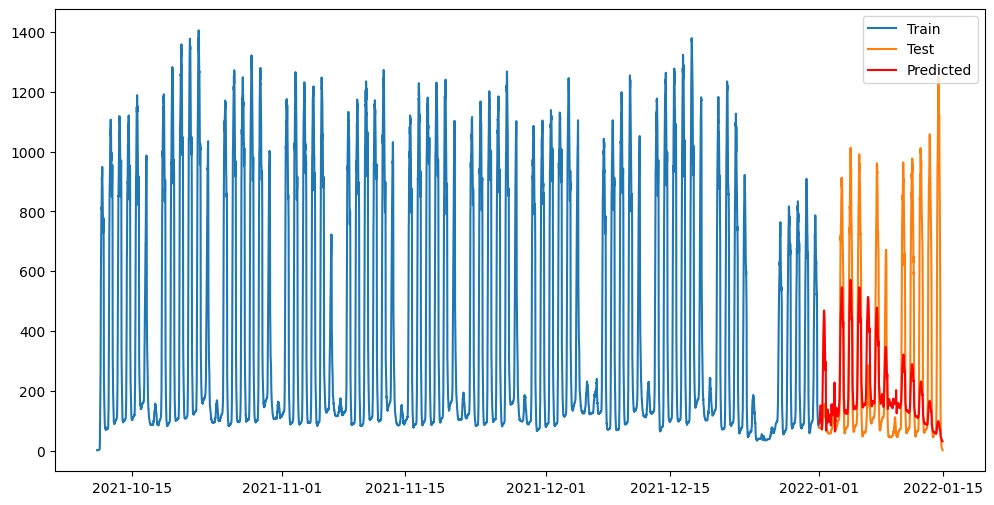

Prophet MAE: 181.51311443018906, RMSE: 284.8461089166238


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Split the data into training and test sets
end_date = pd.to_datetime('2022-01-01')
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Prepare the data for Prophet
train_prophet = train_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})

# Initialize and fit the Prophet model with additional regressors and hyperparameters
prophet_model = Prophet(
    seasonality_mode='multiplicative',
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=10.0
)

# Add additional regressors if available
# prophet_model.add_regressor('additional_feature')

prophet_model.add_seasonality(name='daily', period=1, fourier_order=15)
prophet_model.add_seasonality(name='weekly', period=7, fourier_order=20)
prophet_model.add_seasonality(name='yearly', period=365.25, fourier_order=10)

prophet_model.fit(train_prophet)

# Create a DataFrame to hold future dates for which we want predictions
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='15min')

# Make predictions
prophet_forecast = prophet_model.predict(future)

# Extract the forecast for the test period
prophet_pred = prophet_forecast.set_index('ds')['yhat'][-len(test_data):]

# Print the training, test data, and predictions
print(train_data)
print(test_data)
print(prophet_pred)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='red')
plt.legend()
plt.show()

# Calculate error metrics
mae_prophet = mean_absolute_error(test_data['Parkings'], prophet_pred)
rmse_prophet = np.sqrt(mean_squared_error(test_data['Parkings'], prophet_pred))

print(f'Prophet MAE: {mae_prophet}, RMSE: {rmse_prophet}')


13:26:09 - cmdstanpy - INFO - Chain [1] start processing
13:26:09 - cmdstanpy - INFO - Chain [1] done processing


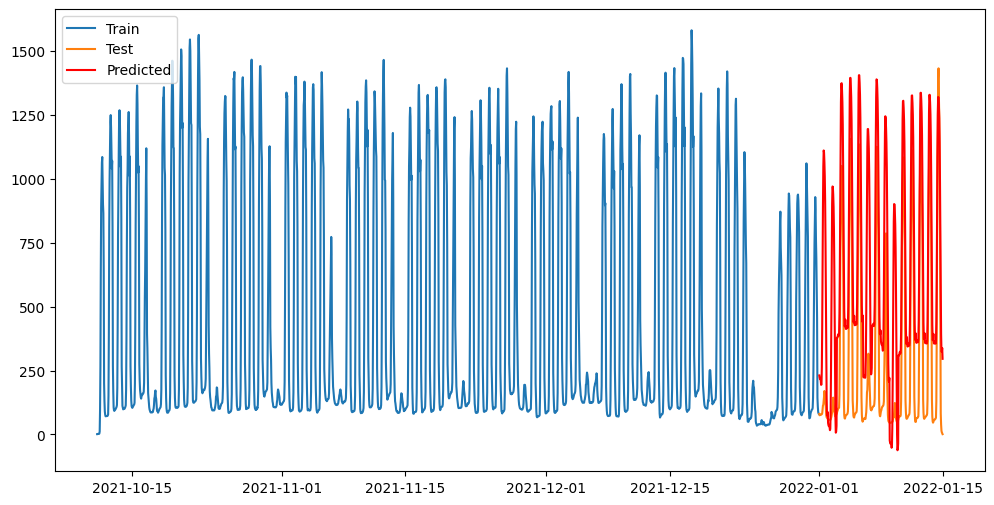

Prophet MAE: 326.35792702056744, RMSE: 380.36914469687434


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Add exogenous features
df['day_of_year'] = df.index.dayofyear
df['weekday'] = df.index.weekday
df['hour'] = df.index.hour

# Filter dates where is_holiday is 1
holidays_df = df[df['is_holiday'] == 1]

# Extract the dates
holiday_dates = holidays_df.index

holidays_df = pd.DataFrame({
  'holiday': 'finnishholidays',
  'ds': pd.to_datetime(holiday_dates),
})

# Split the data into training and test sets
end_date = pd.to_datetime('2022-01-01')
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]


# Prepare the data for Prophet
train_prophet = train_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})
test_prophet = test_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})


# Initialize and fit the Prophet model
prophet_model = Prophet(
    holidays=holidays_df,
    daily_seasonality=True)
    

# Add exogenous features to the model
exogenous_features = ["day_of_year", "weekday", "hour"]
for feature in exogenous_features:
    prophet_model.add_regressor(feature)

    
prophet_model.fit(train_prophet)

# Create a DataFrame to hold future dates for which we want predictions
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='1h')

# Make predictions
prophet_forecast = prophet_model.predict(test_prophet)

# Extract the forecast for the test period
prophet_pred = prophet_forecast.set_index('ds')['yhat'][-len(test_data):]

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='red')
plt.legend()
plt.show()

# Calculate error metrics
mae_prophet = mean_absolute_error(test_data['Parkings'], prophet_pred)
rmse_prophet = np.sqrt(mean_squared_error(test_data['Parkings'], prophet_pred))

print(f'Prophet MAE: {mae_prophet}, RMSE: {rmse_prophet}')


  0%|          | 0/1 [00:00<?, ?it/s]10:44:03 - cmdstanpy - INFO - Chain [1] start processing
10:44:03 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  5.26it/s]
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/prophet/plot.py:546: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  x_plt = df_none['horizon'].astype('timedelta64[ns]').view(np.int64) / float(dt_conversions[i])
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/prophet/plot.py:547: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  x_plt_h = df_h['horizon'].astype('timedelta64[ns]').view(np.int64) / float(dt_conversions[i])


          horizon           mse        rmse         mae      mape     mdape  \
0 1 days 09:00:00  48993.668611  221.345135  183.284115  1.142707  0.650720   
1 1 days 10:00:00  49409.203936  222.281812  186.786597  1.169085  0.717116   
2 1 days 11:00:00  53543.702700  231.395122  197.492955  1.252789  0.738531   
3 1 days 12:00:00  61429.853720  247.850466  212.229347  1.346115  0.777674   
4 1 days 13:00:00  69873.013612  264.335040  227.365675  1.418494  0.849309   

      smape  coverage  
0  0.932010  0.636364  
1  0.950230  0.636364  
2  0.982603  0.606061  
3  1.015035  0.575758  
4  1.043184  0.545455  


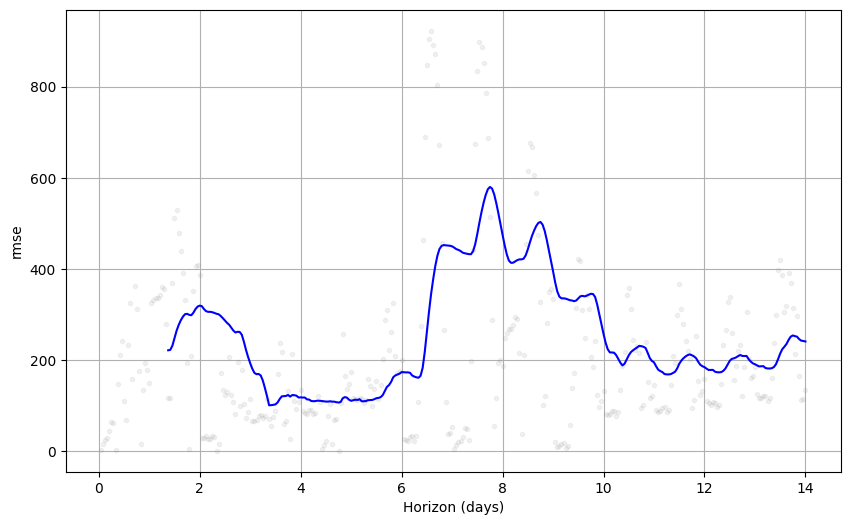

In [3]:
from prophet.diagnostics import cross_validation, performance_metrics

# Define the initial training period, period between each fold, and prediction horizon
initial = '60 days'  # Initial training period
period = '15 days'   # Period between each fold
horizon = '14 days'  # Prediction horizon

# Perform cross-validation
df_cv = cross_validation(prophet_model, initial=initial, period=period, horizon=horizon)

# Evaluate the model's performance
df_p = performance_metrics(df_cv)
print(df_p.head())

# Plot the cross-validation results
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='rmse')
plt.show()
